<a href="https://colab.research.google.com/github/whoCodesEverything/epias-anomaly-detection/blob/main/Epia%C5%9FElektrikT%C3%BCketim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Toplam 672 saatlik veri seti başarıyla oluşturuldu/yüklendi.
-> 672 saatlik veride 8 adet yük anomalisi tespit edildi!


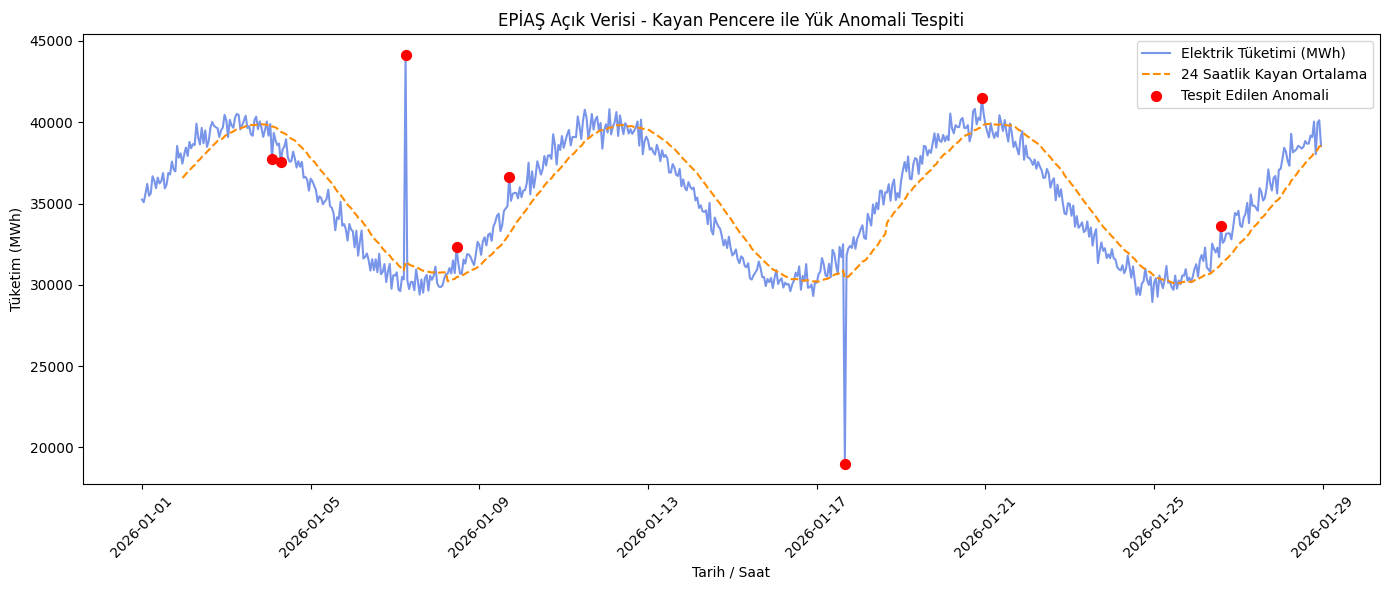

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Simüle Edilmiş 4 Haftalık (672 Saat) Elektrik Tüketim Verisi Oluşturalım
# (Not: Kendi indirdiğin CSV'yi kullanmak istersen: df = pd.read_csv('epias_veri.csv') yapabilirsin)
np.random.seed(42)
tarihler = pd.date_range(start="2026-01-01", periods=672, freq="h")
temel_tuketim = 35000 + np.sin(np.linspace(0, 20, 672)) * 5000

# Verinin içine gerçekçi olması için birkaç ani yük sıçraması (anomali) ekleyelim
gurultu = np.random.normal(0, 500, 672)
gurultu[150] = 14000  # Ani yükseliş anomalisi
gurultu[400] = -13000 # Ani düşüş anomalisi

tuketim = temel_tuketim + gurultu

df = pd.DataFrame({
    'Tarih': tarihler,
    'Tuketim_MWh': tuketim
})

print(f"Toplam {len(df)} saatlik veri seti başarıyla oluşturuldu/yüklendi.")

# 2. Kayan Pencere (Rolling Window) ile Anomali Tespiti
window_size = 24  # 24 saatlik (1 günlük) hareketli ortalama penceresi
df['Rolling_Mean'] = df['Tuketim_MWh'].rolling(window=window_size).mean()
df['Rolling_Std'] = df['Tuketim_MWh'].rolling(window=window_size).std()

# Anomali Eşiği (Ortalamadan 2.5 standart sapma uzaklaşan değerler)
threshold = 2.5
df['Anomali'] = np.abs(df['Tuketim_MWh'] - df['Rolling_Mean']) > (threshold * df['Rolling_Std'])

# Tespit edilen anomali sayısını yazdır
anomaly_count = df['Anomali'].sum()
print(f"-> 672 saatlik veride {anomaly_count} adet yük anomalisi tespit edildi!")

# 3. Sonuçları Görselleştirme
plt.figure(figsize=(14, 6))
plt.plot(df['Tarih'], df['Tuketim_MWh'], label='Elektrik Tüketimi (MWh)', color='royalblue', alpha=0.7)
plt.plot(df['Tarih'], df['Rolling_Mean'], label='24 Saatlik Kayan Ortalama', color='darkorange', linestyle='--')

# Anomalileri kırmızı noktalarla işaretle
anomalies = df[df['Anomali']]
plt.scatter(anomalies['Tarih'], anomalies['Tuketim_MWh'], color='red', s=50, label='Tespit Edilen Anomali', zorder=5)

plt.title('EPİAŞ Açık Verisi - Kayan Pencere ile Yük Anomali Tespiti')
plt.xlabel('Tarih / Saat')
plt.ylabel('Tüketim (MWh)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

# Grafiği göster
plt.show()

# İşlenmiş veriyi CSV olarak indirmek istersen:
# df.to_csv('islenmis_anomali_verisi.csv', index=False)

In [ ]:
df.to_csv('islenmis_anomali_verisi.csv', index=False)


In [ ]:
# Sadece anomalilerin olduğu satırları filtrele
anomali_tablosu = df[df['Anomali']][['Tarih', 'Tuketim_MWh', 'Rolling_Mean']]

# Tablonun sütun isimlerini daha şık hale getirelim
anomali_tablosu.columns = ['Tarih / Saat', 'Gerçekleşen Tüketim (MWh)', 'Beklenen Kayan Ortalama (MWh)']

# Pandas DataFrame'ini ekrana yazdır
display(anomali_tablosu)

,Tarih / Saat,Gerçekleşen Tüketim (MWh),Beklenen Kayan Ortalama (MWh)
74,2026-01-04 02:00:00,37715.880766,39735.449890
79,2026-01-04 07:00:00,37547.048785,39415.949308
150,2026-01-07 06:00:00,44145.038674,31406.708284
179,2026-01-08 11:00:00,32299.226112,30476.479322
209,2026-01-09 17:00:00,36658.109055,33157.964970
400,2026-01-17 16:00:00,18998.537082,30397.281926
478,2026-01-20 22:00:00,41509.097261,39770.780817
614,2026-01-26 14:00:00,33615.782521,31271.925030


In [ ]:
# Ne kadar saptığını hesapla (Mutlak fark / Standart Sapma)
df['Z_Score'] = np.abs(df['Tuketim_MWh'] - df['Rolling_Mean']) / df['Rolling_Std']

# Sadece anomalileri ve z-skorlarını göster
detayli_anomaliler = df[df['Anomali']][['Tarih', 'Tuketim_MWh', 'Z_Score']]
display(detayli_anomaliler)

,Tarih,Tuketim_MWh,Z_Score
74,2026-01-04 02:00:00,37715.880766,3.373713
79,2026-01-04 07:00:00,37547.048785,2.546018
150,2026-01-07 06:00:00,44145.038674,4.561799
179,2026-01-08 11:00:00,32299.226112,2.828916
209,2026-01-09 17:00:00,36658.109055,2.700573
400,2026-01-17 16:00:00,18998.537082,4.430850
478,2026-01-20 22:00:00,41509.097261,2.503857
614,2026-01-26 14:00:00,33615.782521,2.621385


In [ ]:
# İşlenmiş veriyi CSV olarak kaydet
df.to_csv('islenmis_anomali_verisi.csv', index=False)


print("CSV verisi ve grafik başarıyla indirilebilir dosyalara kaydedildi!")

CSV verisi ve grafik başarıyla indirilebilir dosyalara kaydedildi!


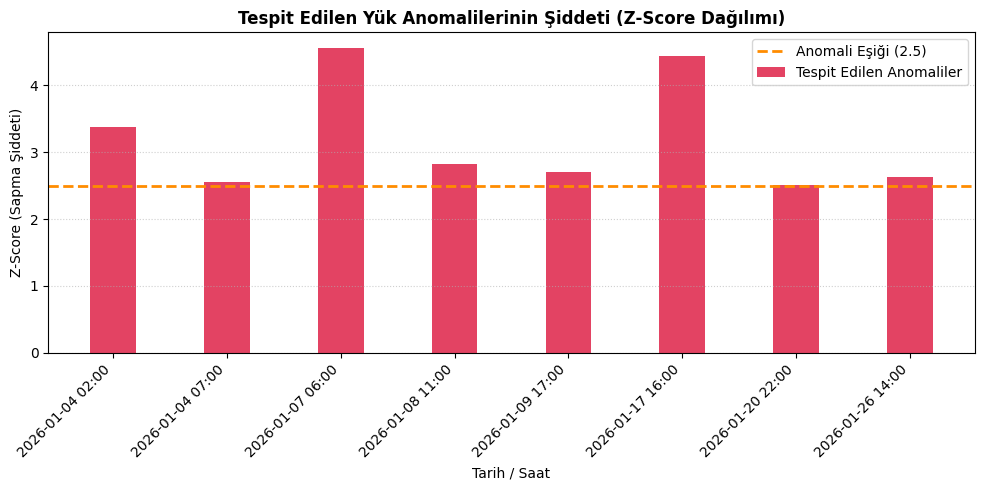

Grafik başarıyla dolu bir şekilde kaydedildi ve gösterildi!


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Tarihleri string formatına çevir
tarih_str = detayli_anomaliler['Tarih'].dt.strftime('%Y-%m-%d %H:%M')
z_scores = detayli_anomaliler['Z_Score']

# Sütun grafiği çizimi
plt.bar(tarih_str, z_scores, color='crimson', width=0.4, alpha=0.8, label='Tespit Edilen Anomaliler')
plt.axhline(y=2.5, color='darkorange', linestyle='--', linewidth=2, label='Anomali Eşiği (2.5)')

# Başlık ve etiketler
plt.title('Tespit Edilen Yük Anomalilerinin Şiddeti (Z-Score Dağılımı)', fontsize=12, fontweight='bold')
plt.xlabel('Tarih / Saat', fontsize=10)
plt.ylabel('Z-Score (Sapma Şiddeti)', fontsize=10)
plt.legend()
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()

# 1. ÖNCE DOSYAYI KAYDET (plt.show() belleği silmeden önce)
plt.savefig('anomali_siddeti_grafigi.png', dpi=300)

# 2. SONRA EKRANDA GÖSTER
plt.show()

print("Grafik başarıyla dolu bir şekilde kaydedildi ve gösterildi!")

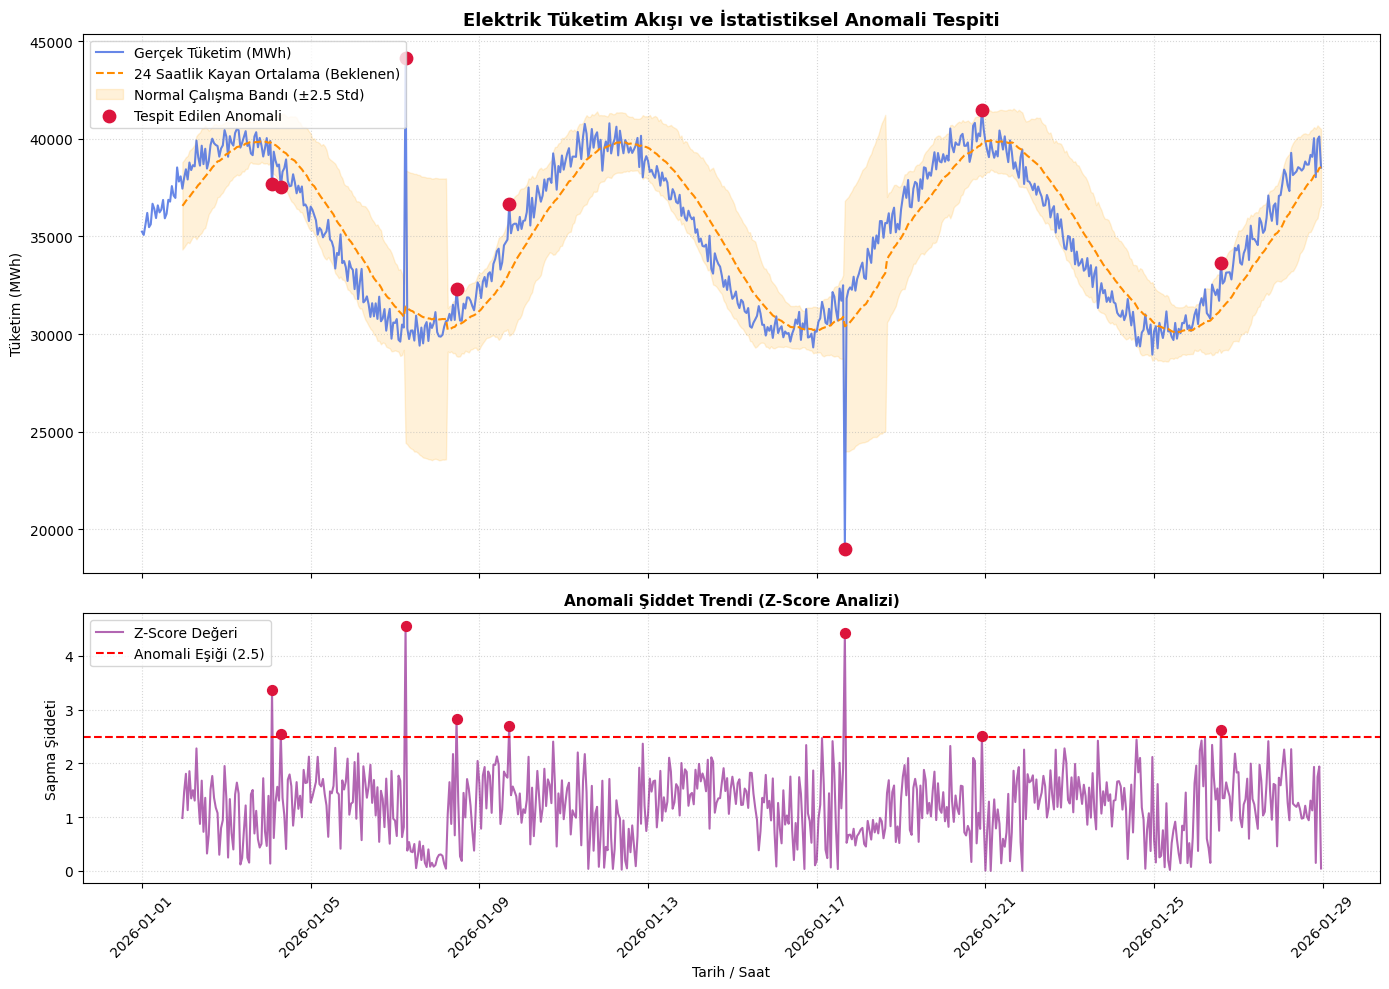

Gelişmiş analitik grafik başarıyla kaydedildi!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Önce Z-Score'u hesapladığımızdan emin olalım (eğer daha önce eklemediyseniz)
df['Z_Score'] = np.abs(df['Tuketim_MWh'] - df['Rolling_Mean']) / df['Rolling_Std']

# İki panelli (alt alta iki grafik) bir figür oluşturalım
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# --- 1. ÜST GRAFİK: Tüketim, Kayan Ortalama ve Güven Aralığı Bandı ---
ax1.plot(df['Tarih'], df['Tuketim_MWh'], label='Gerçek Tüketim (MWh)', color='royalblue', alpha=0.8)
ax1.plot(df['Tarih'], df['Rolling_Mean'], label='24 Saatlik Kayan Ortalama (Beklenen)', color='darkorange', linestyle='--')

# Üst ve alt sınırları hesaplayıp güven bandı (şeffaf alan) oluşturalım
upper_bound = df['Rolling_Mean'] + (2.5 * df['Rolling_Std'])
lower_bound = df['Rolling_Mean'] - (2.5 * df['Rolling_Std'])
ax1.fill_between(df['Tarih'], lower_bound, upper_bound, color='orange', alpha=0.15, label='Normal Çalışma Bandı (±2.5 Std)')

# Anomalileri kırmızı büyük noktalarla işaretle
anomalies = df[df['Anomali']]
ax1.scatter(anomalies['Tarih'], anomalies['Tuketim_MWh'], color='crimson', s=80, label='Tespit Edilen Anomali', zorder=5)

ax1.set_title('Elektrik Tüketim Akışı ve İstatistiksel Anomali Tespiti', fontsize=13, fontweight='bold')
ax1.set_ylabel('Tüketim (MWh)', fontsize=10)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle=':', alpha=0.5)


# --- 2. ALT GRAFİK: Z-Score (Sapma Şiddeti) Trendi ---
ax2.plot(df['Tarih'], df['Z_Score'], color='purple', alpha=0.6, label='Z-Score Değeri')
ax2.axhline(y=2.5, color='red', linestyle='--', linewidth=1.5, label='Anomali Eşiği (2.5)')
ax2.scatter(anomalies['Tarih'], anomalies['Z_Score'], color='crimson', s=50, zorder=5)

ax2.set_title('Anomali Şiddet Trendi (Z-Score Analizi)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Tarih / Saat', fontsize=10)
ax2.set_ylabel('Sapma Şiddeti', fontsize=10)
ax2.legend(loc='upper left', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()

# Önce kaydet, sonra göster
plt.savefig('gelismis_anomali_analizi.png', dpi=300)
plt.show()

print("Gelişmiş analitik grafik başarıyla kaydedildi!")